# Cleaning the Kaggle Data Science Survey (2017–2021) and finding what respondents actually do

**Goal.** Take five years of messy, real survey data, clean it, encode the categorical answers, and pull out insights about how respondents work and what they prefer.

**What you get**

| Output | File |
|---|---|
| Clean, encoded dataset (one row per respondent) | `survey_clean_encoded.csv` |
| Every raw → clean value mapping and every label code | `value_mappings.csv` |
| Column descriptions | `data_dictionary.csv` |
| Top-5 insights dashboard | `top5_insights_dashboard.png` |

**Contents**

1. Setup and load
2. Audit: what is wrong with the raw data?
3. Cleaning pipeline (rows, text, categories, age and generation, salary, flags)
4. Encoding (ordinal scales, label codes, multi-select flags)
5. Validation and export
6. Five insights
7. Dashboard
8. Conclusions and limitations

> **Reading guide.** Every cleaning step follows the same pattern: *problem → fix → check*. Every insight follows: *question → chart → takeaway → caveat*.

## 1. Setup and load

In [1]:
import os, re, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

# ---- settings (the only cell you may need to edit) ----
CSV_NAME = "kaggle_survey_2017_2021.csv"
OUT_DIR  = Path(os.environ.get("OUT_DIR", "outputs"))   # where results are saved
OUT_DIR.mkdir(parents=True, exist_ok=True)
MIN_ANSWERS_FOR_DUP = 10    # a duplicate only counts if the row has at least this many answers (see section 2)

BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2F5D8A", "#E08A2E", "#4C9A6A", "#C0504D", "#8C8C8C", "#7B5EA7"

def find_csv():
    """Look for the CSV in the usual places; unzip the project zip if needed."""
    candidates = [os.environ.get("SURVEY_CSV"), CSV_NAME, f"data/{CSV_NAME}",
                  f"Genaration_wise_data_cleaning/{CSV_NAME}",
                  f"../input/kaggle-data-science-survey-20172021/{CSV_NAME}"]
    for p in candidates:
        if p and Path(p).exists():
            return Path(p)
    for z in Path(".").glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            if any(n.endswith(CSV_NAME) for n in zf.namelist()):
                zf.extractall("data")
                return next(Path("data").rglob(CSV_NAME))
    raise FileNotFoundError(f"Put {CSV_NAME} next to this notebook (or set SURVEY_CSV).")

DATA_PATH = find_csv()
print("Data file:", DATA_PATH.name)

Data file: kaggle_survey_2017_2021.csv


In [2]:
# The first CSV row only holds question codes (Q1, Q2, ...); the second row holds the real question text.
raw = pd.read_csv(DATA_PATH, skiprows=1, low_memory=False, encoding="utf-8-sig")
raw.columns = raw.columns.str.strip()
print(f"{raw.shape[0]:,} respondents x {raw.shape[1]} columns")
raw.groupby("Year").size().rename("respondents").to_frame().T

106,301 respondents x 293 columns


Year,2017,2018,2019,2020,2021
respondents,16716,23859,19717,20036,25973


The questions are long sentences, so we give the columns we use short names. We look columns up by the start of their text instead of by position, which keeps the notebook working if the column order changes.

In [3]:
def find_col(prefix):
    """Return the one column whose name starts with `prefix`."""
    hits = [c for c in raw.columns if c.startswith(prefix)]
    assert len(hits) == 1, f"{prefix!r} matched {len(hits)} columns"
    return hits[0]

C = {  # short name -> raw column
    "year":      "Year",
    "duration":  "Duration (in seconds)",
    "age":       find_col("What is your age"),
    "gender":    find_col("What is your gender"),
    "country":   find_col("In which country"),
    "education": find_col("What is the highest level of formal"),
    "role":      find_col("Select the title most similar"),
    "coding":    find_col("For how many years have you been writing"),
    "industry":  find_col("In what industry"),
    "size":      find_col("What is the size of the company"),
    "ml_adopt":  find_col("Does your current employer incorporate"),
    "salary":    find_col("What is your current yearly compensation"),
}

# Multi-select questions ("select all that apply"): short key -> start of the question text
BLOCKS = {
    "lang":         "What programming languages do you use on a regular basis",
    "ide":          "Which of the following integrated development environments",
    "notebook":     "Which of the following hosted notebook products do you use",
    "viz":          "What data visualization libraries",
    "ml_framework": "Which of the following machine learning frameworks do you use",
    "ml_algo":      "Which of the following ML algorithms",
    "course":       "On which platforms have you begun",
}
print({k: v[:38] + "..." if len(v) > 38 else v for k, v in C.items()})

{'year': 'Year', 'duration': 'Duration (in seconds)', 'age': 'What is your age (# years)?', 'gender': 'What is your gender? - Selected Choice', 'country': 'In which country do you currently resi...', 'education': 'What is the highest level of formal ed...', 'role': 'Select the title most similar to your ...', 'coding': 'For how many years have you been writi...', 'industry': 'In what industry is your current emplo...', 'size': 'What is the size of the company where ...', 'ml_adopt': 'Does your current employer incorporate...', 'salary': 'What is your current yearly compensati...'}


## 2. Audit: what is wrong with the raw data?

Before changing anything we measure the problems. Five things are checked: **empty rows, duplicates, missing values, inconsistent labels, and odd completion times.**

In [4]:
survey_cols = [c for c in raw.columns if c not in (C["year"], C["duration"])]
n_answers   = raw[survey_cols].notna().sum(axis=1)          # how many questions each respondent answered

is_empty    = n_answers == 0
dup_any     = raw.duplicated()                               # identical across every column
dup_real    = dup_any & (n_answers >= MIN_ANSWERS_FOR_DUP)   # identical AND carrying enough answers to be a real copy

by_year = pd.DataFrame({
    "respondents":          raw.groupby("Year").size(),
    "empty rows":           is_empty.groupby(raw["Year"]).sum(),
    "'duplicates' (naive)": dup_any.groupby(raw["Year"]).sum(),
    "real duplicates":      dup_real.groupby(raw["Year"]).sum(),
    "median answers/person": n_answers.groupby(raw["Year"]).median(),
})
by_year

,respondents,empty rows,'duplicates' (naive),real duplicates,median answers/person
Year,,,,,
2017,16716,31,4415,0,6.0
2018,23859,0,18,0,26.0
2019,19717,0,4,0,32.0
2020,20036,0,19,0,38.0
2021,25973,0,0,0,40.0


**Duplicates need care.** A naive `duplicated()` flags thousands of 2017 rows, but the 2017 file only carries about six answers per person (age, gender, country, education, role, coding years). Two different people can easily give the same six answers, so those rows are **not** copies. We only count a duplicate when the rows match completely *and* have at least 10 answers, because matching on that many answers by chance is practically impossible.

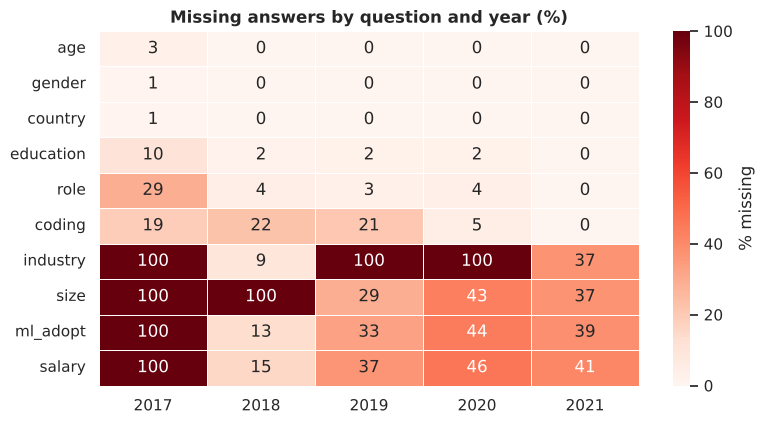

In [5]:
# Missing values: share of respondents with NO answer, per core question and year
core = ["age", "gender", "country", "education", "role", "coding", "industry", "size", "ml_adopt", "salary"]
miss = pd.DataFrame({k: raw[C[k]].isna().groupby(raw["Year"]).mean() * 100 for k in core}).T

fig, ax = plt.subplots(figsize=(8, 4.4))
sns.heatmap(miss, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, linewidths=.5,
            cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing answers by question and year (%)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Two kinds of missing.** A 100% cell means *the question was not asked that year* (for example, salary in 2017). That is different from a respondent who skipped a question. We keep the two apart later: `Not asked` vs `Not answered`.

In [6]:
# Inconsistent labels: how many different spellings does each question have?
def mojibake(s):  # text like "Bachelorâ€™s" is an encoding error
    return s.dropna().astype(str).str.contains("â€", regex=False).sum()

label_audit = pd.DataFrame({
    "distinct labels in raw data": {k: raw[C[k]].nunique() for k in
        ["gender", "country", "education", "role", "coding", "industry", "size", "ml_adopt", "salary"]},
    "broken-encoding cells": {k: mojibake(raw[C[k]]) for k in
        ["gender", "country", "education", "role", "coding", "industry", "size", "ml_adopt", "salary"]},
})
label_audit.index.name = "question"
label_audit

,distinct labels in raw data,broken-encoding cells
question,,
gender,9,0
country,77,0
education,12,71987
role,35,0
coding,20,0
industry,19,0
size,6,0
ml_adopt,6,0
salary,47,0


In [7]:
# Show the actual mess for three questions
for k in ["gender", "education", "coding"]:
    print(f"--- {k} ---")
    print(raw[C[k]].value_counts(dropna=False).head(12).to_string(), "\n")

--- gender ---
What is your gender? - Selected Choice
Male                                                 49178
Man                                                  36387
Female                                               10000
Woman                                                 8768
Prefer not to say                                     1276
Prefer to self-describe                                224
A different identity                                   159
Nonbinary                                              140
NaN                                                     95
Non-binary, genderqueer, or gender non-conforming       74 

--- education ---
What is the highest level of formal education that you have attained or plan to attain within the next 2 years?
Masterâ€™s degree                                                      37395
Bachelorâ€™s degree                                                    29961
Doctoral degree                                                       

In [8]:
# Completion time (only recorded 2018+)
dur = raw[C["duration"]].dropna()
print("Median completion time: %.0f minutes" % (dur.median() / 60))
print("Finished in under 2 minutes WITH 20+ answers (implausibly fast): %d" %
      ((raw[C["duration"]] < 120) & (n_answers >= 20)).sum())
print("Took longer than 24 hours (tab left open):                      %d" % (dur > 86400).sum())

Median completion time: 11 minutes
Finished in under 2 minutes WITH 20+ answers (implausibly fast): 3
Took longer than 24 hours (tab left open):                      2641


### Audit summary

| # | Problem found | What we do |
|---|---|---|
| 1 | A few dozen respondents answered nothing | Drop them |
| 2 | Real duplicate rows (identical, 10+ answers) | Drop them; keep 2017 look-alikes, they are not copies |
| 3 | Same answer spelled many ways (`Male`/`Man`, `United States`/`United States of America`, `1-2 years`/`1 to 2 years`) | Map to one standard label |
| 4 | Broken text encoding (`Bachelorâ€™s`) | Repair |
| 5 | Questions not asked in some years | Mark `Not asked`, separate from `Not answered` |
| 6 | Ages and salaries stored as text bands | Convert to numbers and ordered levels |
| 7 | Implausible completion times | Flag, do not delete |

## 3. Cleaning pipeline

### 3.1 Remove empty rows and real duplicates

In [9]:
keep = ~(is_empty | dup_real)
df = raw.loc[keep, list(C.values())].copy()   # only the columns we need; the original row number stays as the index
n_year = df[C["year"]]             # shortcut used by the helpers below

print(f"Rows before: {len(raw):,}")
print(f"  removed empty rows:     {is_empty.sum():,}")
print(f"  removed real duplicates: {(dup_real & ~is_empty).sum():,}")
print(f"Rows after:  {len(df):,}")

Rows before: 106,301
  removed empty rows:     31
  removed real duplicates: 0
Rows after:  106,270


### 3.2 Standardise categories

One helper does the work for every question:

1. repair broken text and trim spaces,
2. map spelling variants to one label,
3. fill gaps with `Not asked` (question absent that year) or `Not answered` (respondent skipped it).

In [10]:
def fix_text(s):
    """Repair encoding errors and stray spaces."""
    return (s.astype("string")
             .str.replace("â€™", "'", regex=False)
             .str.replace("â€˜", "'", regex=False)
             .str.strip())

def standardise(col, mapping=None):
    """Clean one question column. Returns a text Series with no missing values."""
    raw_vals = fix_text(df[C[col]])
    asked = raw_vals.notna().groupby(n_year).transform("any")        # was it asked that year?
    out = raw_vals.replace(mapping) if mapping else raw_vals
    out = out.fillna("Not answered").where(asked, "Not asked")
    return out.astype(str)

def check_unmapped(series, allowed, name):
    """Fail loudly if a raw label slipped through the mapping."""
    left = sorted(set(series.unique()) - set(allowed) - {"Not answered", "Not asked"})
    assert not left, f"{name}: unmapped labels {left}"

MAPS = {}   # collects every mapping for the export in section 5

In [11]:
# ---- Gender ----
GENDER = {"Male": "Man", "Man": "Man", "Female": "Woman", "Woman": "Woman",
          "Nonbinary": "Non-binary / self-described",
          "Non-binary, genderqueer, or gender non-conforming": "Non-binary / self-described",
          "Prefer to self-describe": "Non-binary / self-described",
          "A different identity": "Non-binary / self-described",
          "Prefer not to say": "Prefer not to say"}
df["gender"] = standardise("gender", GENDER)
check_unmapped(df["gender"], GENDER.values(), "gender")

# ---- Country ----   ("Republic of China" in the 2017 form means Taiwan)
COUNTRY = {"United States of America": "United States", "Viet Nam": "Vietnam",
           "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
           "Iran, Islamic Republic of...": "Iran", "Republic of Korea": "South Korea",
           "Hong Kong (S.A.R.)": "Hong Kong", "People 's Republic of China": "China",
           "Republic of China": "Taiwan", "I do not wish to disclose my location": "Undisclosed"}
df["country"] = standardise("country", COUNTRY)

# ---- Education ----
EDUCATION = {"Some college/university study without earning a bachelor's degree": "Some college",
             "No formal education past high school": "High school",
             "I did not complete any formal education past high school": "High school",
             "Bachelor's degree": "Bachelor's", "Master's degree": "Master's",
             "Doctoral degree": "Doctorate", "Professional doctorate": "Professional degree",
             "I prefer not to answer": "Prefer not to answer"}
df["education"] = standardise("education", EDUCATION)
check_unmapped(df["education"], list(EDUCATION.values()) + ["Professional degree"], "education")

# ---- Job title ----   (we keep Machine Learning Engineer separate from Data Scientist: they are different jobs)
ROLE = {"Currently not employed": "Unemployed", "Not employed": "Unemployed",
        "Product Manager": "Product/Project Manager", "Program/Project Manager": "Product/Project Manager",
        "Software Developer/Software Engineer": "Software Engineer",
        "Scientist/Researcher": "Research Scientist", "Researcher": "Research Scientist",
        "Developer Advocate": "Developer Relations/Advocacy"}
df["role"] = standardise("role", ROLE)
rare = df.loc[~df["role"].isin(["Not answered", "Not asked"]), "role"].value_counts(normalize=True)
rare = rare[rare < 0.01].index                                  # titles below 1% of respondents
df["role_group"] = df["role"].where(~df["role"].isin(rare), "Other")

# ---- Years of coding ----
CODING = {"< 1 years": "< 1 year", "Less than a year": "< 1 year",
          "1-2 years": "1-3 years", "1 to 2 years": "1-3 years",
          "3 to 5 years": "3-5 years", "6 to 10 years": "5-10 years",
          "More than 10 years": "10+ years", "10-20 years": "10+ years", "20+ years": "10+ years",
          "20-30 years": "10+ years", "30-40 years": "10+ years", "40+ years": "10+ years",
          "I have never written code": "Never",
          "I have never written code and I do not want to learn": "Never",
          "I have never written code but I want to learn": "Never",
          "I don't write code to analyze data": "Never"}
df["coding_exp"] = standardise("coding", CODING)

# ---- Employer questions ----
INDUSTRY = {"I am a student": "Student", "Computers/Technology": "Technology",
            "Academics/Education": "Academics", "Accounting/Finance": "Finance",
            "Manufacturing/Fabrication": "Manufacturing", "Medical/Pharmaceutical": "Medical",
            "Government/Public Service": "Government", "Energy/Mining": "Energy",
            "Online Service/Internet-based Services": "Internet business",
            "Online Business/Internet-based Sales": "Internet business",
            "Retail/Sales": "Retail", "Insurance/Risk Assessment": "Insurance", "Marketing/CRM": "Marketing",
            "Broadcasting/Communications": "Communications", "Shipping/Transportation": "Shipping",
            "Non-profit/Service": "Non-profit", "Military/Security/Defense": "Security/Defense",
            "Hospitality/Entertainment/Sports": "Entertainment"}
df["industry"] = standardise("industry", INDUSTRY)

SIZE = {"0-49 employees": "0-49", "50-249 employees": "50-249", "250-999 employees": "250-999",
        "1000-9,999 employees": "1,000-9,999", "10,000 or more employees": "10,000+", "> 10,000 employees": "10,000+"}
df["company_size"] = standardise("size", SIZE)

ADOPT = {"No (we do not use ML methods)": "No ML",
         "We are exploring ML methods (and may one day put a model into production)": "Exploring ML",
         "We use ML methods for generating insights (but do not put working models into production)": "Insights only",
         "We recently started using ML methods (i.e., models in production for less than 2 years)": "In production < 2 yrs",
         "We have well established ML methods (i.e., models in production for more than 2 years)": "In production 2+ yrs",
         "I do not know": "Don't know"}
df["ml_adopt"] = standardise("ml_adopt", ADOPT)

for name, m in [("gender", GENDER), ("country", COUNTRY), ("education", EDUCATION), ("role", ROLE),
                ("coding_exp", CODING), ("industry", INDUSTRY), ("company_size", SIZE), ("ml_adopt", ADOPT)]:
    MAPS[name] = m

df[["gender", "education", "coding_exp", "company_size"]].describe().loc[["count", "unique", "top"]]

,gender,education,coding_exp,company_size
count,106270,106270,106270,106270
unique,5,8,7,7
top,Man,Master's,1-3 years,Not asked


In [12]:
# Check: how many distinct labels remain after cleaning vs before?
def n_clean(col):  return df.loc[~df[col].isin(["Not answered", "Not asked"]), col].nunique()
LABELS = pd.DataFrame({
    "before": [raw[C[k]].nunique() for k in ["gender", "country", "education", "role", "coding", "industry", "size", "ml_adopt"]],
    "after":  [n_clean(c) for c in ["gender", "country", "education", "role", "coding_exp", "industry", "company_size", "ml_adopt"]],
}, index=["gender", "country", "education", "role", "coding_exp", "industry", "company_size", "ml_adopt"])
LABELS["fewer labels"] = LABELS["before"] - LABELS["after"]
LABELS

,before,after,fewer labels
gender,9,4,5
country,77,69,8
education,12,7,5
role,35,28,7
coding_exp,20,6,14
industry,19,18,1
company_size,6,5,1
ml_adopt,6,6,0


### 3.3 Age and generation

Age is stored as a band (`25-29`). We keep the band, add its midpoint, and estimate a birth year as `survey year - midpoint`. Generations follow the usual cut-offs: **Gen Z** born 1997 or later, **Millennial** 1981–1996, **Gen X** 1965–1980, **Baby Boomer** 1964 or earlier.

> **Caution.** Because ages are bands, a generation here is an *estimate*, and the same band can fall into different generations in different years (the 22–24 band is Millennial in 2019 and Gen Z in 2020). So we use **generation for comparisons inside one year** and **age bands for trends across years**.

In [13]:
AGE_MID = {"18-21": 19.5, "22-24": 23, "25-29": 27, "30-34": 32, "35-39": 37, "40-44": 42,
           "45-49": 47, "50-54": 52, "55-59": 57, "60-69": 64.5, "70+": 72}     # 70+ midpoint is an assumption
AGE_ORDER = list(AGE_MID)

df["age_band"]  = standardise("age")
df["age_level"] = df["age_band"].map({b: i + 1 for i, b in enumerate(AGE_ORDER)}).astype("Int8")
df["age_mid"]   = df["age_band"].map(AGE_MID)
birth = df[C["year"]] - df["age_mid"]
df["birth_year_est"] = birth.round().astype("Int16")
df["generation"] = np.select([birth >= 1997, birth >= 1981, birth >= 1965, birth.notna()],
                             ["Gen Z", "Millennial", "Gen X", "Baby Boomer"], default="Not answered")

pd.crosstab(df["age_band"], df["generation"]).reindex(AGE_ORDER)

generation,Baby Boomer,Gen X,Gen Z,Millennial,Not answered
age_band,,,,,
18-21,0,0,15159,0,0
22-24,0,0,8480,11182,0
25-29,0,0,0,23748,0
30-34,0,0,0,16144,0
35-39,0,2033,0,8835,0
40-44,0,7327,0,0,0
45-49,0,4996,0,0,0
50-54,0,3514,0,0,0
55-59,2112,0,0,0,0


### 3.4 Salary

Salary arrives as 47 different text bands (`$0-999`, `10-20,000`, `500,000+`, ...). One parser turns each into a number (the band's midpoint). Salary was not asked in 2017, and many people prefer not to say.

> **Caution.** These are nominal US dollars, not adjusted for cost of living, and each year uses different band widths. We use salary for broad comparisons, not for exact figures.

In [14]:
def parse_salary(label):
    """'25,000-29,999' -> 27499.5 | '10-20,000' -> 15000 | '500,000+' -> 500000 | undisclosed -> NaN"""
    if not isinstance(label, str) or label.lower().startswith("i do not"):
        return np.nan
    nums = [float(n.replace(",", "")) for n in re.findall(r"\d[\d,]*", label)]
    if len(nums) == 1:                      # open-ended top band, use its lower edge
        return nums[0]
    low, high = nums[:2]
    if low < 1000 and high >= 10000:        # "10-20,000" means 10,000-20,000
        low *= 1000
    return (low + high) / 2

df["salary_usd"] = df[C["salary"]].map(parse_salary)
df["salary_band"] = pd.cut(df["salary_usd"], [-1, 10_000, 25_000, 50_000, 100_000, np.inf], right=False,
                           labels=["< $10k", "$10-25k", "$25-50k", "$50-100k", "$100k+"])

parsed = df[C["salary"]].dropna().unique()
print("distinct salary labels:", len(parsed), "| parsed to a number:", sum(pd.notna(parse_salary(x)) for x in parsed))
df.groupby(C["year"])["salary_usd"].agg(answered="count", median="median")

distinct salary labels: 47 | parsed to a number: 46


,answered,median
Year,,
2017,0,NaN
2018,15429,25000.0
2019,12497,27499.5
2020,10729,17499.5
2021,15391,12499.5


### 3.5 Quality flags (flag, do not delete)

Completion time cannot prove a response is bad, so we keep the rows and add flags the analyst can use.

In [15]:
df["duration_sec"] = df[C["duration"]]
df["flag_too_fast"] = ((df["duration_sec"] < 120) & (n_answers[df.index] >= 20)).astype("int8")  # 20+ answers in under 2 min
df["flag_too_slow"] = (df["duration_sec"] > 86_400).astype("int8")                                 # open for more than 24 h
df[["flag_too_fast", "flag_too_slow"]].sum().to_frame("rows flagged").T

,flag_too_fast,flag_too_slow
rows flagged,3,2641


## 4. Encoding

Models and charts need numbers, so each categorical question gets the encoding that fits its type:

| Type | Example | Encoding |
|---|---|---|
| **Ordered** | education, coding experience, company size | **Ordinal level** (1, 2, 3, ...) that respects the order |
| **Unordered** | gender, country, role, generation | **Label code**: an arbitrary ID per label (alphabetical), *not* a ranking |
| **Select-all-that-apply** | languages, IDEs, ML frameworks | One **0/1 column per choice**, e.g. `lang__Python` |

The original text columns are kept next to the codes so nothing is hidden.

### 4.1 Ordinal levels

In [16]:
ORDERS = {   # column -> (levels from lowest to highest, first number)
    "education_level":    ("education",    ["High school", "Some college", "Bachelor's", "Master's",
                                            "Professional degree", "Doctorate"], 1),   # assumption: professional degree sits between Master's and Doctorate
    "coding_exp_level":   ("coding_exp",   ["Never", "< 1 year", "1-3 years", "3-5 years", "5-10 years", "10+ years"], 0),
    "company_size_level": ("company_size", ["0-49", "50-249", "250-999", "1,000-9,999", "10,000+"], 1),
    "ml_adopt_level":     ("ml_adopt",     ["No ML", "Exploring ML", "Insights only",
                                            "In production < 2 yrs", "In production 2+ yrs"], 0),   # "Don't know" stays empty
}
LEVEL_ROWS = []
for new_col, (src, order, start) in ORDERS.items():
    levels = {label: i + start for i, label in enumerate(order)}
    df[new_col] = df[src].map(levels).astype("Int8")          # labels outside the scale (Not answered, Don't know) -> empty
    LEVEL_ROWS += [(src, "ordinal level", label, lvl) for label, lvl in levels.items()]

df["salary_level"] = (df["salary_band"].cat.codes + 1).where(df["salary_band"].notna()).astype("Int8")
LEVEL_ROWS += [("salary_band", "ordinal level", b, i + 1) for i, b in enumerate(df["salary_band"].cat.categories)]
LEVEL_ROWS += [("age_band", "ordinal level", b, i + 1) for i, b in enumerate(AGE_ORDER)]

df[["education", "education_level"]].drop_duplicates().sort_values("education_level")

,education,education_level
38,High school,1
6,Some college,2
0,Bachelor's,3
1,Master's,4
80,Professional degree,5
3,Doctorate,6
5,Prefer not to answer,<NA>
26104,Not answered,<NA>


### 4.2 Label codes for unordered categories

In [17]:
CODE_ROWS = []
for col in ["gender", "country", "role", "industry", "generation"]:
    labels = sorted(df[col].unique())                         # alphabetical, so codes are reproducible
    codes = {label: i for i, label in enumerate(labels)}
    df[f"{col}_code"] = df[col].map(codes).astype("Int16")
    CODE_ROWS += [(col, "label code", label, code_) for label, code_ in codes.items()]

df[["gender", "gender_code"]].drop_duplicates().sort_values("gender_code")

,gender,gender_code
0,Man,0
32,Non-binary / self-described,1
89977,Not answered,2
66,Prefer not to say,3
5,Woman,4


### 4.3 Select-all-that-apply questions → 0/1 columns

Two details make these columns honest:

* **Skipped is not "no".** If a respondent skipped the whole question, the flags stay *empty* (not 0).
* **Not offered is not "no".** If an option was not on that year's form (for example C++ in 2018), it stays empty for that year.

So a share like "% using Python" is always measured among people who actually answered and could have chosen it.

In [18]:
CHOICE_FIX = {"Xgboost": "XGBoost", "Kaggle Learn Courses": "Kaggle Learn",
              "Plotly / Plotly Express": "Plotly", "Ggplot / ggplot2": "ggplot2"}

slug = lambda s: re.sub(r"[^0-9a-zA-Z]+", "_", s.replace("+", " plus ")).strip("_")   # C++ -> C_plus_plus

def clean_choice(raw_col):
    """'... - Selected Choice -  Jupyter (JupyterLab, ...) ' -> 'Jupyter'"""
    choice = raw_col.split(" - Selected Choice - ")[-1]
    choice = re.sub(r"\s*\(.*?\)\s*$", "", choice).strip()    # drop trailing explanation in brackets
    return CHOICE_FIX.get(choice, choice)

def multiselect_flags(key, prefix):
    cols = [c for c in raw.columns if c.startswith(prefix) and " - Selected Choice - " in c]
    picked = raw.loc[df.index, cols].notna()
    picked.columns = [f"{key}__{slug(clean_choice(c))}" for c in cols]
    assert picked.columns.is_unique, f"duplicate choice names in {key}"
    answered = picked.any(axis=1).to_numpy()[:, None]                       # did they answer this question at all?
    offered  = picked.groupby(df[C["year"]]).transform("any").to_numpy()    # was the option on the form that year?
    mask = pd.DataFrame(answered & offered, index=picked.index, columns=picked.columns)
    return picked.astype("Int8").where(mask)

flags = pd.concat([multiselect_flags(k, p) for k, p in BLOCKS.items()], axis=1)
FLAG_COLS = {k: [c for c in flags.columns if c.startswith(k + "__")] for k in BLOCKS}
pd.Series({k: len(v) for k, v in FLAG_COLS.items()}, name="0/1 columns").to_frame().T

,lang,ide,notebook,viz,ml_framework,ml_algo,course
0/1 columns,13,11,14,12,16,12,12


## 5. Validation and export

We assert the key promises of the cleaning instead of trusting it by eye.

In [19]:
base_cols = ["age_band", "age_level", "age_mid", "birth_year_est", "generation", "generation_code",
             "gender", "gender_code", "country", "country_code",
             "education", "education_level", "role", "role_code", "role_group",
             "coding_exp", "coding_exp_level", "industry", "industry_code",
             "company_size", "company_size_level", "ml_adopt", "ml_adopt_level",
             "salary_usd", "salary_band", "salary_level",
             "duration_sec", "flag_too_fast", "flag_too_slow"]

clean = pd.concat([df[[C["year"]]].rename(columns={C["year"]: "year"}), df[base_cols], flags], axis=1)
clean.insert(0, "row_id", clean.index)
clean["salary_band"] = clean["salary_band"].astype("string")

text_cols = ["age_band", "generation", "gender", "country", "education", "role", "coding_exp",
             "industry", "company_size", "ml_adopt"]
checks = {
    "rows = raw - empty - real duplicates":   len(clean) == len(raw) - int((is_empty | dup_real).sum()),
    "row_id is unique":                        clean["row_id"].is_unique,
    "no broken encoding left":                 not any(clean[c].str.contains("â€", regex=False).any() for c in text_cols),
    "no empty text cells (all labelled)":      not clean[text_cols].isna().any().any(),
    "gender has <= 5 labels":                  clean["gender"].nunique() <= 5,
    "education has <= 8 labels":               clean["education"].nunique() <= 8,
    "ordinal levels inside their range":       clean["coding_exp_level"].dropna().between(0, 5).all()
                                               and clean["education_level"].dropna().between(1, 6).all(),
    "flags are only 0, 1 or empty":            set(np.unique(flags.to_numpy(dtype=float)[~np.isnan(flags.to_numpy(dtype=float))])) <= {0.0, 1.0},
    "every year still present":                set(clean["year"]) == set(raw["Year"]),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "a validation check failed"
print(f"\nClean table: {clean.shape[0]:,} rows x {clean.shape[1]} columns")

PASS  rows = raw - empty - real duplicates
PASS  row_id is unique
PASS  no broken encoding left
PASS  no empty text cells (all labelled)
PASS  gender has <= 5 labels
PASS  education has <= 8 labels
PASS  ordinal levels inside their range
PASS  flags are only 0, 1 or empty
PASS  every year still present

Clean table: 106,270 rows x 121 columns


In [20]:
# We do NOT guess (impute) missing answers. Instead every gap is labelled, so nothing is hidden.
gaps = pd.DataFrame({"Not answered (skipped)": (clean[text_cols] == "Not answered").sum(),
                     "Not asked (question absent that year)": (clean[text_cols] == "Not asked").sum()})
gaps.loc["salary_usd (undisclosed or not asked)"] = [clean["salary_usd"].isna().sum(), 0]
gaps

,Not answered (skipped),Not asked (question absent that year)
age_band,414,0
generation,414,0
gender,64,0
country,90,0
education,2952,0
role,7183,0
coding_exp,13485,0
industry,11822,56438
company_size,24070,40544
ml_adopt,28607,16685


In [21]:
# Export: dataset, mappings, data dictionary
mappings = pd.DataFrame(
    [(var, "raw -> clean", k, v) for var, m in MAPS.items() for k, v in m.items()] + LEVEL_ROWS + CODE_ROWS,
    columns=["variable", "kind", "from", "to"])

dictionary = pd.DataFrame([
    ("row_id", "Original row number in the raw file (for traceability)"),
    ("year", "Survey year, 2017-2021"),
    ("age_band / age_level / age_mid", "Age band as asked; its order (1-11); its midpoint in years"),
    ("birth_year_est / generation", "Estimated birth year (year - age midpoint) and generation (approximate, see 3.3)"),
    ("gender / gender_code", "Man, Woman, Non-binary / self-described, Prefer not to say, Not answered; plus label code"),
    ("country / country_code", "Standardised country; plus label code"),
    ("education / education_level", "Highest education; ordinal 1 (High school) to 6 (Doctorate)"),
    ("role / role_code / role_group", "Standardised job title; label code; titles under 1% grouped as Other"),
    ("coding_exp / coding_exp_level", "Years of coding; ordinal 0 (Never) to 5 (10+ years)"),
    ("industry / industry_code", "Employer industry; label code"),
    ("company_size / company_size_level", "Employer size; ordinal 1 (0-49) to 5 (10,000+)"),
    ("ml_adopt / ml_adopt_level", "Does the employer use ML; ordinal 0 (No ML) to 4 (in production 2+ years)"),
    ("salary_usd / salary_band / salary_level", "Midpoint of the salary band in nominal USD; 5 bands; band order 1-5"),
    ("duration_sec", "Seconds to complete the survey (2018+)"),
    ("flag_too_fast / flag_too_slow", "1 = 20+ answers in under 2 minutes / 1 = over 24 hours"),
    ("<block>__<choice>", "1 = chosen, 0 = not chosen, empty = skipped or not offered. Blocks: " + ", ".join(BLOCKS)),
], columns=["column", "meaning"])

clean.to_csv(OUT_DIR / "survey_clean_encoded.csv", index=False)
mappings.to_csv(OUT_DIR / "value_mappings.csv", index=False)
dictionary.to_csv(OUT_DIR / "data_dictionary.csv", index=False)
for f in ["survey_clean_encoded.csv", "value_mappings.csv", "data_dictionary.csv"]:
    print(f"saved {OUT_DIR.name}/{f}  ({(OUT_DIR / f).stat().st_size / 1e6:.1f} MB)")
dictionary

saved outputs/survey_clean_encoded.csv  (32.4 MB)
saved outputs/value_mappings.csv  (0.0 MB)
saved outputs/data_dictionary.csv  (0.0 MB)


,column,meaning
0,row_id,Original row number in the raw file (for trace...
1,year,"Survey year, 2017-2021"
2,age_band / age_level / age_mid,Age band as asked; its order (1-11); its midpo...
3,birth_year_est / generation,Estimated birth year (year - age midpoint) and...
4,gender / gender_code,"Man, Woman, Non-binary / self-described, Prefe..."
5,country / country_code,Standardised country; plus label code
6,education / education_level,Highest education; ordinal 1 (High school) to ...
7,role / role_code / role_group,Standardised job title; label code; titles und...
8,coding_exp / coding_exp_level,Years of coding; ordinal 0 (Never) to 5 (10+ y...
9,industry / industry_code,Employer industry; label code


## 6. Five insights about respondent behaviour

Every chart below comes from the clean table, so the numbers are reproducible. Percentages for select-all questions are calculated **among people who answered that question**, which is fairer than dividing by everyone.

In [22]:
# Helpers shared by all insights
def end_labels(ax, table, fmt="{:.0f}%", colors=None, dx=0.08):
    """Write each line's last value at its right end, nudging labels apart so they never overlap."""
    ends = sorted((table[c].dropna().iloc[-1], c) for c in table.columns)
    lo, hi = ax.get_ylim(); gap = (hi - lo) * 0.05
    x_end, ys = table.dropna(how="all").index[-1], []
    for v, _ in ends:
        ys.append(v if not ys else max(v, ys[-1] + gap))
    for (v, c), y in zip(ends, ys):
        color = colors[list(table.columns).index(c)] if colors else None
        ax.text(x_end + dx, y, f"{c} {fmt.format(v)}", va="center", fontsize=9, color=color)

def clean_axes(ax, ylabel=None):
    ax.set_xlabel(""); ax.set_ylabel(ylabel or "")
    ax.grid(axis="x", visible=False)

### Insight 1: respondents are much younger than in 2017

**Question.** Is the typical respondent changing over the five years?

Aged 18-24: 23% in 2017 -> 37% in 2021
Aged 35+:   33% in 2017 -> 31% in 2021


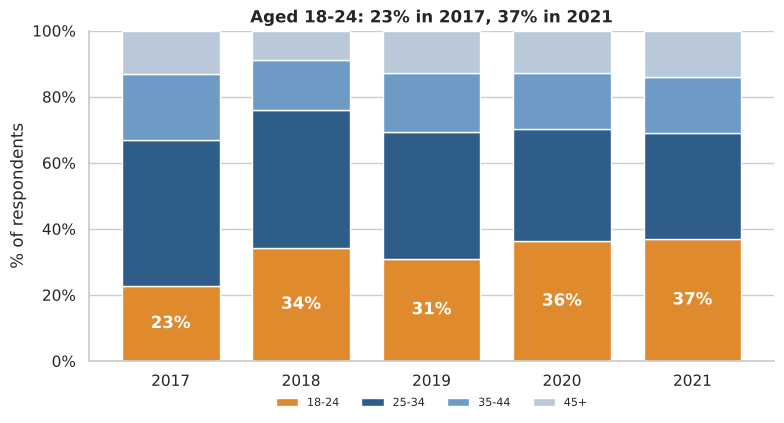

In [23]:
GROUPS = {"18-24": ["18-21", "22-24"], "25-34": ["25-29", "30-34"], "35-44": ["35-39", "40-44"],
          "45+": ["45-49", "50-54", "55-59", "60-69", "70+"]}
band_to_group = {b: g for g, bands in GROUPS.items() for b in bands}

known_age = clean[clean["age_band"].isin(band_to_group)]
t1 = (pd.crosstab(known_age["year"], known_age["age_band"].map(band_to_group), normalize="index") * 100)[list(GROUPS)]

def plot_age(ax):
    t1.plot(kind="bar", stacked=True, ax=ax, width=.75, color=["#E08A2E", "#2F5D8A", "#6E9BC5", "#B9C9DA"], legend=False)
    for i, v in enumerate(t1["18-24"]):
        ax.text(i, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    ax.set_title(f"Aged 18-24: {t1['18-24'].loc[2017]:.0f}% in 2017, {t1['18-24'].loc[2021]:.0f}% in 2021")
    ax.set_xticklabels(t1.index, rotation=0); clean_axes(ax, "% of respondents")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, 100)
    ax.legend(title="", loc="upper center", bbox_to_anchor=(.5, -0.08), ncol=4, frameon=False, fontsize=8)

fig, ax = plt.subplots(figsize=(8, 4.4)); plot_age(ax); plt.tight_layout(); plt.show()

young = t1["18-24"]
print(f"Aged 18-24: {young.loc[2017]:.0f}% in 2017 -> {young.loc[2021]:.0f}% in 2021")
print(f"Aged 35+:   {(100 - t1[['18-24', '25-34']].sum(axis=1)).loc[2017]:.0f}% in 2017 -> {(100 - t1[['18-24', '25-34']].sum(axis=1)).loc[2021]:.0f}% in 2021")

**What we see**
- The share of respondents aged 18–24 went from **23% in 2017 to 37% in 2021**. It jumped in 2018 (34%), dipped in 2019 (31%), then settled at 36–37%.
- The 35+ share barely moved (33% → 31%), so the growth came from new, young entrants, not from the community ageing out.

**So what.** A young base explains many other trends in the survey (lower median pay, shorter coding experience, more students). Compare groups *within* a year, or control for age, before reading a trend as "the field changed".

**Caveat.** The survey is voluntary and run on Kaggle, so it describes Kaggle's audience, not all data professionals.

### Insight 2: Python is near-universal, R is fading, and the generations differ

**Question.** Which languages do respondents use, and does it depend on age group?

Python: 86% (2018) -> 89% (2021)
R:      37% (2018) -> 22% (2021)
2021 Python: Gen Z 92% vs Baby Boomers 78%
2021 R:      Gen Z 16% vs Baby Boomers 32%
Respondents in the 2021 generation comparison: {'Gen Z': 9332, 'Millennial': 10204, 'Gen X': 3906, 'Baby Boomer': 1180}


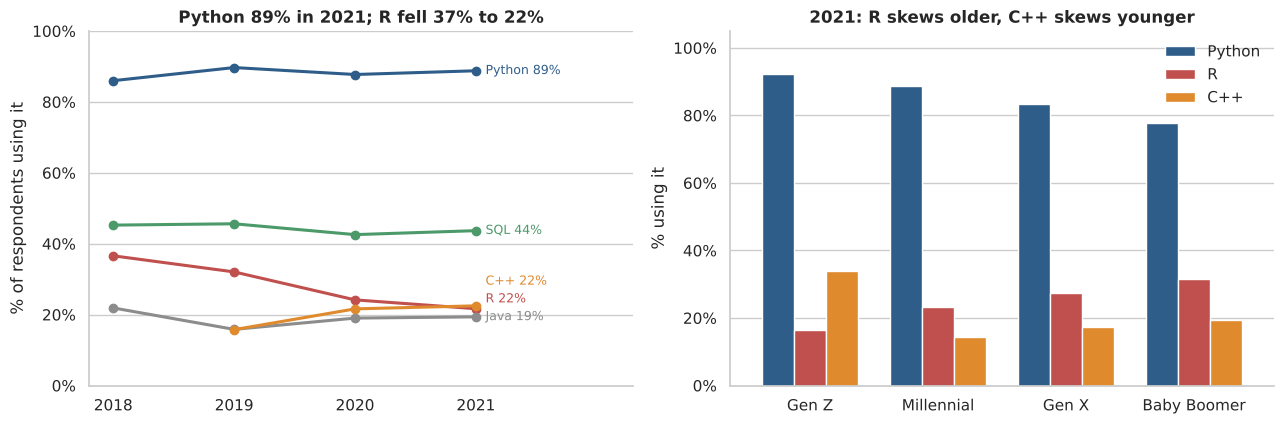

In [24]:
LANG_COL = {"Python": "lang__Python", "SQL": "lang__SQL", "R": "lang__R", "Java": "lang__Java", "C++": "lang__C_plus_plus"}
LANGS = list(LANG_COL)
t2 = (clean.groupby("year")[list(LANG_COL.values())].mean() * 100).loc[2018:2021]   # empty = option not on that year's form
t2.columns = LANGS

gen_order = ["Gen Z", "Millennial", "Gen X", "Baby Boomer"]
d21 = clean[(clean["year"] == 2021) & clean["lang__Python"].notna() & clean["generation"].isin(gen_order)]
t2g = (d21.groupby("generation")[[LANG_COL[l] for l in ["Python", "R", "C++"]]].mean() * 100).loc[gen_order]
t2g.columns = ["Python", "R", "C++"]

def plot_lang_trend(ax):
    cols = [BLUE, GREEN, RED, GREY, ORANGE]
    for l, c in zip(LANGS, cols):
        ax.plot(t2.index, t2[l], marker="o", color=c, lw=2.2, label=l)
    ax.set_xticks(t2.index); ax.set_xlim(2017.8, 2022.3); ax.set_ylim(0, 100)
    end_labels(ax, t2, colors=cols)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_title(f"Python {t2['Python'].loc[2021]:.0f}% in 2021; R fell {t2['R'].loc[2018]:.0f}% to {t2['R'].loc[2021]:.0f}%"); clean_axes(ax, "% of respondents using it")

def plot_lang_gen(ax):
    t2g.plot(kind="bar", ax=ax, color=[BLUE, RED, ORANGE], width=.75)
    ax.set_xticklabels(t2g.index, rotation=0); ax.set_ylim(0, 105)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_title("2021: R skews older, C++ skews younger"); clean_axes(ax, "% using it"); ax.legend(frameon=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4)); plot_lang_trend(axes[0]); plot_lang_gen(axes[1])
plt.tight_layout(); plt.show()

print(f"Python: {t2['Python'].loc[2018]:.0f}% (2018) -> {t2['Python'].loc[2021]:.0f}% (2021)")
print(f"R:      {t2['R'].loc[2018]:.0f}% (2018) -> {t2['R'].loc[2021]:.0f}% (2021)")
print(f"2021 Python: Gen Z {t2g.loc['Gen Z','Python']:.0f}% vs Baby Boomers {t2g.loc['Baby Boomer','Python']:.0f}%")
print(f"2021 R:      Gen Z {t2g.loc['Gen Z','R']:.0f}% vs Baby Boomers {t2g.loc['Baby Boomer','R']:.0f}%")
print("Respondents in the 2021 generation comparison:", d21["generation"].value_counts().reindex(gen_order).to_dict())

**What we see**
- **Python** is used by about nine in ten respondents (86% in 2018, 89% in 2021). **SQL** is steady near 44%.
- **R** fell from 37% to 22%, and C++ rose into the same range as R by 2021.
- Generations differ in 2021: **Gen Z uses Python more (92% vs 78% for Baby Boomers), R less (16% vs 32%), and C++ far more (34% vs 14–19% for the other generations)**.

**So what.** Newcomers learn Python first (often alongside C++ in university courses). R stays strong among older practitioners, so it is shrinking in share rather than disappearing.

**Caveat.** Generation is estimated from age bands (section 3.3). C++ was not on the 2018 form, so its line starts in 2019.

### Insight 3: Google Colab caught up with Kaggle's own notebooks

**Question.** Where do people run their notebooks, and is that shifting?

Colab:  31% (2018) -> 56% (2021)
Kaggle: 54% (2018) -> 54% (2021)
Binder/JupyterHub: 44% (2018) -> 10% (2021)
Years Colab is ahead of Kaggle: [2020, 2021]


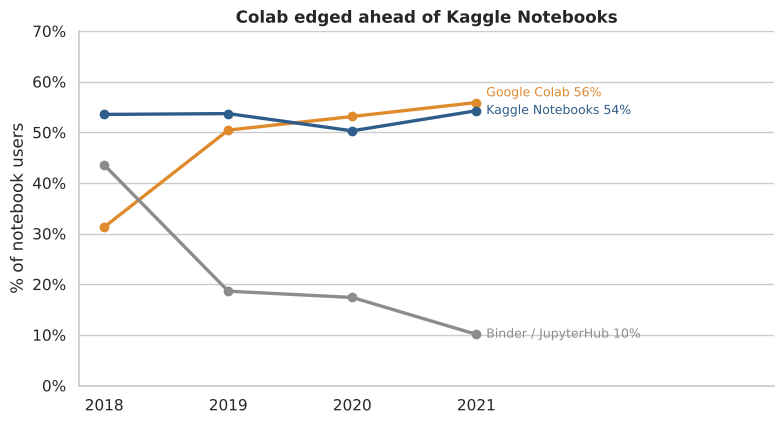

In [25]:
NB = {"Colab Notebooks": "Google Colab", "Kaggle Notebooks": "Kaggle Notebooks", "Binder_JupyterHub": "Binder / JupyterHub"}
nb_cols = {c: [k for k in FLAG_COLS["notebook"] if k.endswith("__" + slug(n))][0]
           for c, n in zip(NB.values(), NB)}
t3 = (clean.groupby("year")[list(nb_cols.values())].mean() * 100).loc[2018:2021]
t3.columns = list(nb_cols)

def plot_notebooks(ax):
    cols = [ORANGE, BLUE, GREY]
    for c, col in zip(t3.columns, cols):
        ax.plot(t3.index, t3[c], marker="o", color=col, lw=2.4)
    ax.set_xticks(t3.index); ax.set_xlim(2017.8, 2023.4); ax.set_ylim(0, 70)
    end_labels(ax, t3, colors=cols)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_title("Colab edged ahead of Kaggle Notebooks"); clean_axes(ax, "% of notebook users")

fig, ax = plt.subplots(figsize=(8, 4.4)); plot_notebooks(ax); plt.tight_layout(); plt.show()

print(f"Colab:  {t3['Google Colab'].loc[2018]:.0f}% (2018) -> {t3['Google Colab'].loc[2021]:.0f}% (2021)")
print(f"Kaggle: {t3['Kaggle Notebooks'].loc[2018]:.0f}% (2018) -> {t3['Kaggle Notebooks'].loc[2021]:.0f}% (2021)")
print(f"Binder/JupyterHub: {t3['Binder / JupyterHub'].loc[2018]:.0f}% (2018) -> {t3['Binder / JupyterHub'].loc[2021]:.0f}% (2021)")
print("Years Colab is ahead of Kaggle:", list(t3.index[t3["Google Colab"] > t3["Kaggle Notebooks"]]))

**What we see**
- **Google Colab** rose from 31% to 56% of notebook users and has been ahead of Kaggle's own notebooks since 2020 (narrowly in 2021: 56% vs 54%).
- Kaggle Notebooks stayed flat at about 54%.
- **Binder / JupyterHub** fell from 44% to 10%: people moved from self-hosted setups to free hosted ones.

**So what.** Free hosted GPUs lowered the cost of entry, which fits the younger audience in Insight 1.

**Caveat.** Kaggle runs the survey, so Kaggle Notebooks users are probably over-represented. The 2018 form also listed fewer products, so 2018 is not perfectly comparable.

### Insight 4: experience raises pay, but where you live matters even more

**Question.** How does pay grow with years of coding, and does the country change the picture?

We use 2019–2021 (similar salary bands), people who are employed, and a stated salary. Students and unemployed respondents are excluded. "Rest of world" means every known country except the United States.

Respondents used: {'Rest of world': 28230, 'United States': 5102}
US median grows $65k -> $137k (2.1x) from under 1 year to 10+ years
Rest-of-world median grows $4k -> $45k
A US coder in year one ($65k) out-earns a rest-of-world coder with 10+ years ($45k)


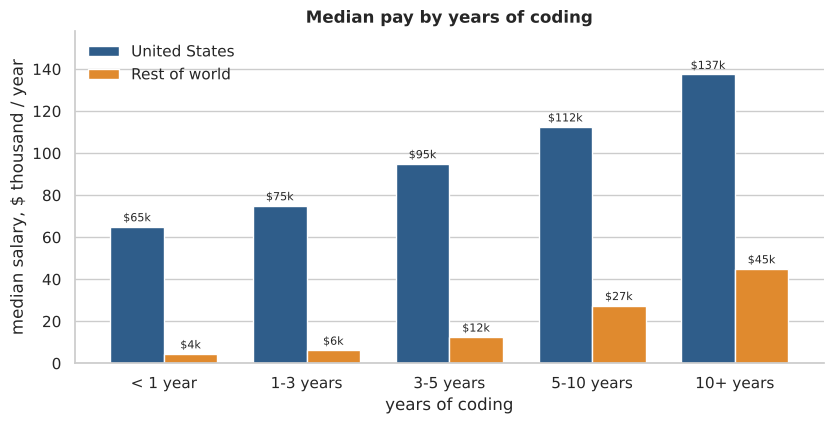

In [26]:
EXP_ORDER = ["< 1 year", "1-3 years", "3-5 years", "5-10 years", "10+ years"]
pay = clean[(clean["year"] >= 2019) & clean["salary_usd"].notna()
            & ~clean["role"].isin(["Student", "Unemployed", "Not answered", "Not asked"])
            & clean["coding_exp"].isin(EXP_ORDER)
            & ~clean["country"].isin(["Other", "Undisclosed", "Not answered"])].copy()
pay["region"] = np.where(pay["country"] == "United States", "United States", "Rest of world")

t4 = (pay.groupby(["coding_exp", "region"])["salary_usd"].median().unstack().loc[EXP_ORDER] / 1000)
n4 = pay.groupby("region").size()

def plot_pay(ax):
    t4[["United States", "Rest of world"]].plot(kind="bar", ax=ax, color=[BLUE, ORANGE], width=.75)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="$%.0fk", fontsize=8, padding=2)
    ax.set_xticklabels(t4.index, rotation=0); ax.set_ylim(0, t4.max().max() * 1.15)
    ax.set_title("Median pay by years of coding"); clean_axes(ax, "median salary, $ thousand / year")
    ax.set_xlabel("years of coding"); ax.legend(frameon=False)

fig, ax = plt.subplots(figsize=(8.5, 4.4)); plot_pay(ax); plt.tight_layout(); plt.show()

print(f"Respondents used: {n4.to_dict()}")
print(f"US median grows ${t4.loc['< 1 year','United States']:.0f}k -> ${t4.loc['10+ years','United States']:.0f}k "
      f"({t4.loc['10+ years','United States'] / t4.loc['< 1 year','United States']:.1f}x) from under 1 year to 10+ years")
print(f"Rest-of-world median grows ${t4.loc['< 1 year','Rest of world']:.0f}k -> ${t4.loc['10+ years','Rest of world']:.0f}k")
print(f"A US coder in year one (${t4.loc['< 1 year','United States']:.0f}k) out-earns a rest-of-world coder with 10+ years (${t4.loc['10+ years','Rest of world']:.0f}k)")

**What we see**
- In the US the median salary rises from **$65k (under 1 year of coding) to $137k (10+ years)**, about 2.1 times.
- Outside the US the same ladder runs from about **$4k to $45k**.
- Geography beats experience: a US coder in their **first year ($65k) out-earns a rest-of-world coder with 10+ years ($45k)**.

**So what.** Never compare raw salaries across countries or years. Any pay analysis of this survey needs a country control.

**Caveat.** Salaries are band midpoints in nominal USD, so medians are coarse, and job mix differs between regions. This shows association, not that experience *causes* the pay.

### Insight 5: bigger companies are far more likely to run ML in production

**Question.** Does company size change how seriously a company uses machine learning? (2021, respondents who gave a definite answer; "Don't know" is excluded.)

Respondents: 13,240
ML in production: 24% in companies with 0-49 staff vs 58% in companies with 10,000+
'No ML at all': 30% in the smallest companies vs 12% in the largest


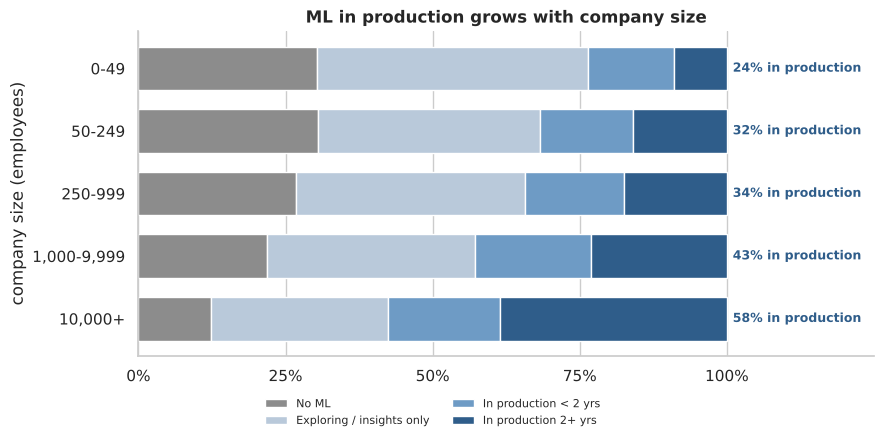

In [27]:
SIZE_ORDER = ["0-49", "50-249", "250-999", "1,000-9,999", "10,000+"]
STAGES = ["No ML", "Exploring / insights only", "In production < 2 yrs", "In production 2+ yrs"]
ml = clean[(clean["year"] == 2021) & clean["company_size"].isin(SIZE_ORDER) & clean["ml_adopt_level"].notna()].copy()
ml["stage"] = ml["ml_adopt"].replace({"Exploring ML": "Exploring / insights only", "Insights only": "Exploring / insights only"})
t5 = (pd.crosstab(ml["company_size"], ml["stage"], normalize="index") * 100).loc[SIZE_ORDER, STAGES]
in_prod = t5[["In production < 2 yrs", "In production 2+ yrs"]].sum(axis=1)

def plot_ml(ax):
    t5.plot(kind="barh", stacked=True, ax=ax, width=.7, color=[GREY, "#B9C9DA", "#6E9BC5", BLUE], legend=False)
    for i, v in enumerate(in_prod):
        ax.text(101, i, f"{v:.0f}% in production", va="center", fontsize=9, fontweight="bold", color=BLUE)
    ax.set_xlim(0, 125); ax.set_xticks(range(0, 101, 25))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_title("ML in production grows with company size"); ax.set_ylabel("company size (employees)"); ax.set_xlabel("")
    ax.grid(axis="y", visible=False); ax.invert_yaxis()          # smallest companies on top
    ax.legend(title="", loc="upper center", bbox_to_anchor=(.4, -0.1), ncol=2, frameon=False, fontsize=8)

fig, ax = plt.subplots(figsize=(9, 4.6)); plot_ml(ax); plt.tight_layout(); plt.show()

print(f"Respondents: {len(ml):,}")
print(f"ML in production: {in_prod.loc['0-49']:.0f}% in companies with 0-49 staff vs {in_prod.loc['10,000+']:.0f}% in companies with 10,000+")
print(f"'No ML at all': {t5.loc['0-49','No ML']:.0f}% in the smallest companies vs {t5.loc['10,000+','No ML']:.0f}% in the largest")

**What we see**
- Only **24%** of respondents at companies with 0–49 employees say ML runs in production, against **58%** at companies with 10,000+ employees.
- "No ML at all" shows the reverse: 30% in the smallest companies and 12% in the largest.
- The rise is steady across all five size bands, not a single jump.

**So what.** Company size is a strong signal of ML maturity: larger companies have the data, budget, and teams to put models into production.

**Caveat.** This is each respondent's own view of their employer, for one year only. "Don't know" answers are excluded.

## 7. Summary dashboard

The five insights plus a panel that shows what the cleaning did. It reuses the same plotting functions as section 6, so the dashboard can never disagree with the detailed charts.

saved outputs/top5_insights_dashboard.png


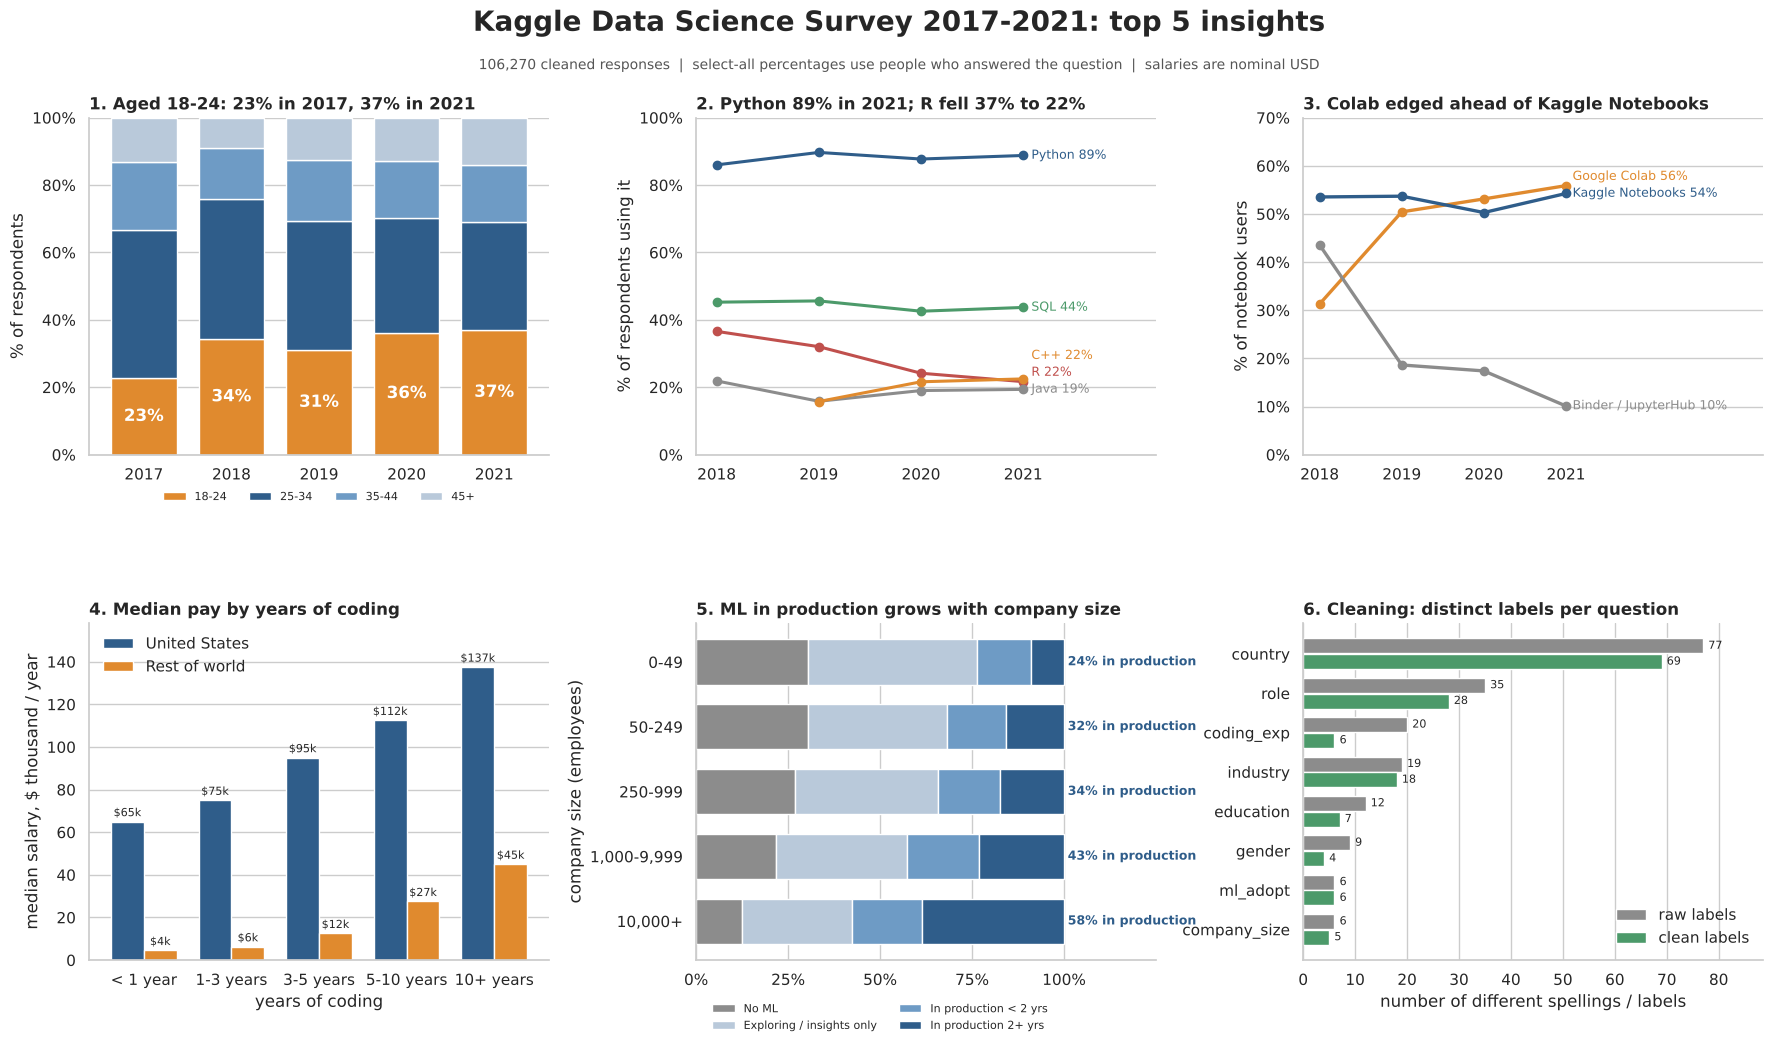

In [28]:
fig = plt.figure(figsize=(18, 10.8))
gs = fig.add_gridspec(2, 3, hspace=.5, wspace=.32, top=.87, left=.05, right=.98, bottom=.09)
axes = [fig.add_subplot(gs[i // 3, i % 3]) for i in range(6)]

plot_age(axes[0]); plot_lang_trend(axes[1]); plot_notebooks(axes[2]); plot_pay(axes[3]); plot_ml(axes[4])

# Panel 6: what the cleaning achieved
ax = axes[5]
L = LABELS.sort_values("before")
y = np.arange(len(L))
ax.barh(y + .2, L["before"], height=.38, color=GREY, label="raw labels")
ax.barh(y - .2, L["after"], height=.38, color=GREEN, label="clean labels")
for i, (b, a) in enumerate(zip(L["before"], L["after"])):
    ax.text(b + 1, i + .2, str(b), va="center", fontsize=8); ax.text(a + 1, i - .2, str(a), va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(L.index); ax.set_xlim(0, L["before"].max() * 1.15)
ax.set_title("Cleaning: distinct labels per question"); ax.set_xlabel("number of different spellings / labels")
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")

for i, a in enumerate(axes):                    # number the panels and left-align their titles
    title = a.get_title()
    a.set_title("", loc="center"); a.set_title(f"{i + 1}. {title}", loc="left")

fig.suptitle("Kaggle Data Science Survey 2017-2021: top 5 insights", fontsize=20, fontweight="bold", y=.97)
fig.text(.5, .915, f"{len(clean):,} cleaned responses  |  select-all percentages use people who answered the question  |  "
                   "salaries are nominal USD", ha="center", fontsize=10, color="#555")
fig.savefig(OUT_DIR / "top5_insights_dashboard.png", dpi=150, bbox_inches="tight", facecolor="white")
print(f"saved {OUT_DIR.name}/top5_insights_dashboard.png")
plt.show()

## 8. Conclusions and limitations

### What cleaning did
- **31 empty rows** removed. **0 real duplicates** were found: the 4,456 "duplicates" a naive check reports are almost all 2017 respondents who simply gave the same six demographic answers.
- Spellings were unified: gender 9 → 4 labels, education 12 → 7, years of coding 20 → 6, job titles 35 → 28, countries 77 → 69. Broken text (`Bachelorâ€™s`, 71,987 cells) was repaired.
- Missing answers were **labelled, not guessed**: `Not asked` (question absent that year) vs `Not answered` (skipped).
- Ordered answers became **ordinal levels**, unordered answers became **label codes**, and select-all questions became **0/1 columns** that stay empty (not 0) when skipped or not offered.

### What the data says
1. Respondents are much younger than in 2017 (18–24: 23% → 37%).
2. Python is near-universal (~89%), R is fading (37% → 22%), and Gen Z leans on Python and C++.
3. Google Colab edged ahead of Kaggle Notebooks; Binder / JupyterHub collapsed.
4. Pay rises with experience, but US vs rest of world is the larger gap.
5. ML in production climbs with company size (24% → 58%).

### Limits to keep in mind
- **Self-selected audience.** Voluntary survey on Kaggle, not a sample of all data professionals.
- **Questionnaire changes.** Options and wording change by year. The check below shows why we did not use the IDE trend.
- **Estimated fields.** Generation comes from age bands; salary is a band midpoint in nominal USD.

In [29]:
# Trend-break check: IDE answers jump in 2021, which looks like a questionnaire change, not real behaviour
ide_check = (clean.groupby("year")[["ide__Jupyter", "ide__Visual_Studio_Visual_Studio_Code"]].mean() * 100).round(0).loc[2018:2021]
ide_check.columns = ["Jupyter %", "Visual Studio / VS Code %"]
ide_check

,Jupyter %,Visual Studio / VS Code %
year,,
2018,75.0,42.0
2019,75.0,32.0
2020,68.0,15.0
2021,25.0,56.0


Jupyter falls by more than half in one year while Visual Studio / VS Code jumps in 2021 after dipping in 2020. Jumps that size in a single year point to a **change in how the question was asked**, so we treat the IDE trend as unreliable and build no insight on it. Spotting a break like this is part of cleaning too.

### How to reuse this notebook
- Put `kaggle_survey_2017_2021.csv` next to the notebook (or set `SURVEY_CSV`), then **Run All**. Results are saved in `outputs/`.
- To analyse something new, start from `survey_clean_encoded.csv`: every question is already standardised and encoded.